# 04 — Final Evaluation on the Held-out Test Set

The tuned LightGBM from `03_modelling.ipynb` is evaluated **once** on the sealed test set
(20% of lots, 34,585 wafers, never used for training or tuning).

1. Validation (cross-validation) vs test scores — does performance hold up on unseen lots?
2. Per-class results and confusion matrix
3. Business view: defect vs no-defect
4. Error analysis: which classes, which wafer sizes, what do the mistakes look like?
5. Confidence: can high-confidence predictions be auto-routed and the rest sent to an engineer?

In [1]:
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import ListedColormap
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix, f1_score,
                             precision_score, recall_score)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

sns.set_theme(style="whitegrid")
FIG_DIR = ROOT / "reports" / "figures"
WAFER_CMAP = ListedColormap(["white", "#9ecae1", "#d62728"])
CLASS_ORDER = ["none", "Edge-Ring", "Edge-Loc", "Center", "Loc",
               "Scratch", "Random", "Donut", "Near-full"]

def savefig(name):
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

In [2]:
bundle = joblib.load(ROOT / "models" / "lgbm_tuned.joblib")
model, FEATURES = bundle["model"], bundle["features"]
print("Best hyperparameters:", bundle["best_params"])

feats = pd.read_parquet(ROOT / "data" / "features.parquet")
test = feats[feats["split"] == "test"]
X_test, y_test = test[FEATURES], test["failureType"].to_numpy()
print(f"Test set: {len(test):,} wafers from {test['lotName'].nunique():,} lots")

# --- the one and only use of the test set ---
proba = model.predict_proba(X_test)
classes = np.asarray(model.classes_)
y_pred = classes[proba.argmax(axis=1)]
confidence = proba.max(axis=1)

Best hyperparameters: {'n_estimators': 676, 'learning_rate': 0.06623659776144764, 'num_leaves': 77, 'min_child_samples': 8, 'subsample': 0.7799016533479063, 'colsample_bytree': 0.5870266456536466, 'reg_lambda': 2.339586455122247, 'class_weight': 'balanced'}
Test set: 34,585 wafers from 2,161 lots


## 1. Validation vs test

In [3]:
def summary(y_true, y_pred):
    d_true, d_pred = y_true != "none", y_pred != "none"
    return {
        "macro_F1": f1_score(y_true, y_pred, average="macro"),
        "weighted_F1": f1_score(y_true, y_pred, average="weighted"),
        "accuracy": accuracy_score(y_true, y_pred),
        "defect_recall": recall_score(d_true, d_pred),
        "defect_precision": precision_score(d_true, d_pred),
    }

oof = pd.read_parquet(ROOT / "data" / "oof_predictions.parquet")
val = summary(oof["y_true"].to_numpy(), oof["4 LightGBM (tuned)"].to_numpy())
tst = summary(y_test, y_pred)
base = summary(y_test, np.full(len(y_test), "none"))
val_vs_test = pd.DataFrame({"validation (5-fold CV)": val, "test": tst, "baseline on test (always none)": base})
val_vs_test.to_csv(ROOT / "reports" / "test_metrics.csv")
val_vs_test.round(3)

,validation (5-fold CV),test,baseline on test (always none)
macro_F1,0.896,0.901,0.102
weighted_F1,0.979,0.980,0.784
accuracy,0.979,0.980,0.852
defect_recall,0.951,0.955,0.000
defect_precision,0.948,0.947,0.000


A small gap between validation and test means the lot-grouped cross-validation gave an honest estimate:
the model generalises to lots it has never seen.

## 2. Per-class results

In [4]:
report = pd.DataFrame(classification_report(y_test, y_pred, labels=CLASS_ORDER, output_dict=True)).T
report.loc[CLASS_ORDER, ["precision", "recall", "f1-score", "support"]].round(3)

,precision,recall,f1-score,support
none,0.992,0.991,0.991,29480.0
Edge-Ring,0.991,0.988,0.989,1936.0
Edge-Loc,0.834,0.901,0.866,1038.0
Center,0.943,0.938,0.940,859.0
Loc,0.798,0.780,0.789,719.0
Scratch,0.795,0.745,0.769,239.0
Random,0.940,0.913,0.927,173.0
Donut,0.874,0.874,0.874,111.0
Near-full,0.938,1.000,0.968,30.0


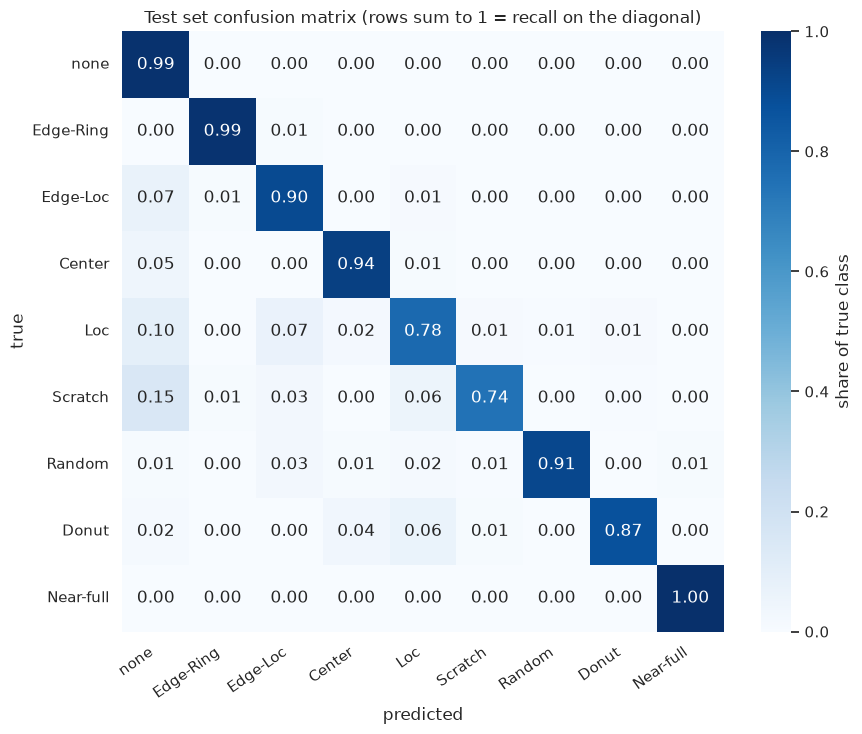

In [5]:
cm = confusion_matrix(y_test, y_pred, labels=CLASS_ORDER)
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1,
            xticklabels=CLASS_ORDER, yticklabels=CLASS_ORDER, cbar_kws={"label": "share of true class"}, ax=ax)
ax.set(xlabel="predicted", ylabel="true", title="Test set confusion matrix (rows sum to 1 = recall on the diagonal)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout(); savefig("confusion_matrix_test"); plt.show()

In [6]:
# Most frequent mistakes (off-diagonal), in absolute wafer counts
errs = pd.DataFrame(cm, index=CLASS_ORDER, columns=CLASS_ORDER).stack().rename("count").reset_index()
errs.columns = ["true", "predicted", "count"]
errs = errs[errs["true"] != errs["predicted"]].sort_values("count", ascending=False)
errs["share_of_true_class"] = errs.apply(lambda r: r["count"] / cm[CLASS_ORDER.index(r["true"])].sum(), axis=1)
errs.head(10).round(3)

,true,predicted,count,share_of_true_class
2,none,Edge-Loc,105,0.004
4,none,Loc,95,0.003
18,Edge-Loc,none,75,0.072
36,Loc,none,69,0.096
38,Loc,Edge-Loc,50,0.070
27,Center,none,42,0.049
45,Scratch,none,37,0.155
5,none,Scratch,33,0.001
3,none,Center,27,0.001
11,Edge-Ring,Edge-Loc,19,0.010


## 3. Business view — defect vs no defect

In [7]:
d_true = np.where(y_test != "none", "defect", "none")
d_pred = np.where(y_pred != "none", "defect", "none")
cm2 = pd.DataFrame(confusion_matrix(d_true, d_pred, labels=["defect", "none"]),
                   index=["true defect", "true none"], columns=["flagged defect", "passed as none"])
display(cm2)

missed = cm2.loc["true defect", "passed as none"]
false_alarms = cm2.loc["true none", "flagged defect"]
flagged = cm2["flagged defect"].sum()
print(f"Defect recall:    {tst['defect_recall']:.1%} of real defect wafers are flagged ({missed:,} missed)")
print(f"Defect precision: {tst['defect_precision']:.1%} of flagged wafers really have a defect "
      f"({false_alarms:,} false alarms)")
print(f"Engineer review load: {flagged:,} of {len(y_test):,} wafers flagged "
      f"({flagged / len(y_test):.1%}) instead of reviewing all of them")

# Of the defects that were flagged, how often is the defect *type* right?
both = (d_true == "defect") & (d_pred == "defect")
print(f"Correct defect type when a real defect is flagged: {(y_test[both] == y_pred[both]).mean():.1%}")

,flagged defect,passed as none
true defect,4873,232
true none,271,29209


Defect recall:    95.5% of real defect wafers are flagged (232 missed)
Defect precision: 94.7% of flagged wafers really have a defect (271 false alarms)
Engineer review load: 5,144 of 34,585 wafers flagged (14.9%) instead of reviewing all of them
Correct defect type when a real defect is flagged: 96.0%


## 4. Error analysis

### By wafer size

In [8]:
test_df = test[["lotName", "dieSize", "failureType"]].copy()
test_df["pred"], test_df["confidence"] = y_pred, confidence
test_df["size_band"] = pd.qcut(test_df["dieSize"], 4, labels=["small", "medium", "large", "very large"])

by_size = test_df.groupby("size_band", observed=True).apply(
    lambda g: pd.Series({
        "wafers": len(g),
        "dies (range)": f"{int(g['dieSize'].min())}–{int(g['dieSize'].max())}",
        "defect share": (g["failureType"] != "none").mean(),
        "macro_F1": f1_score(g["failureType"], g["pred"], average="macro"),
        "defect_recall": recall_score(g["failureType"] != "none", g["pred"] != "none"),
    }), include_groups=False)
by_size

,wafers,dies (range),defect share,macro_F1,defect_recall
size_band,,,,,
small,9490,54–533,0.091781,0.861610,0.936854
medium,7852,542–793,0.077687,0.852717,0.918033
large,9006,796–1256,0.148346,0.871096,0.941617
very large,8237,1286–22372,0.277771,0.926159,0.978584


### What do the mistakes look like?

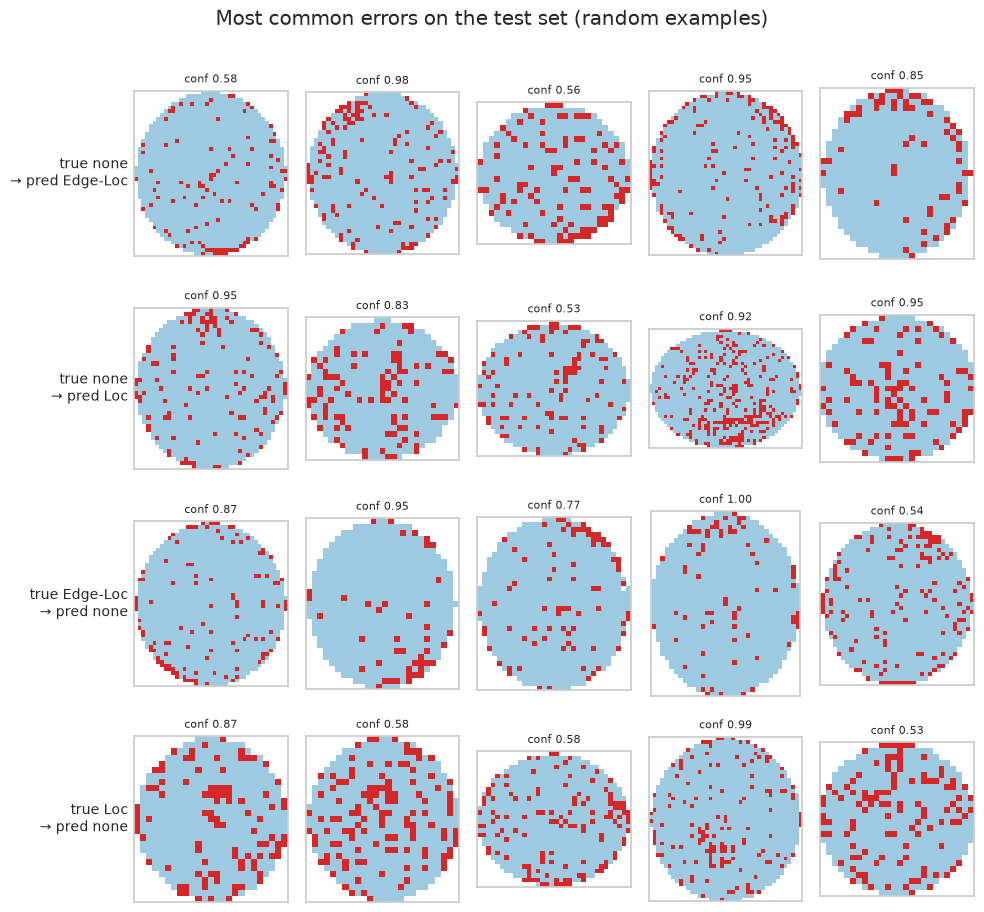

In [9]:
maps = pd.read_pickle(ROOT / "data" / "labelled.pkl")["waferMap"]   # same row order as features.parquet
pairs = list(errs.head(4)[["true", "predicted"]].itertuples(index=False, name=None))
rng = np.random.default_rng(0)

fig, axes = plt.subplots(len(pairs), 5, figsize=(10, 2.3 * len(pairs)))
for r, (t, p) in enumerate(pairs):
    idx = test_df.index[(test_df["failureType"] == t) & (test_df["pred"] == p)]
    for c, i in enumerate(rng.choice(idx, min(5, len(idx)), replace=False)):
        axes[r, c].imshow(maps.iloc[i], cmap=WAFER_CMAP, vmin=0, vmax=2, interpolation="nearest")
        axes[r, c].set_title(f"conf {test_df.at[i, 'confidence']:.2f}", fontsize=8)
    for c in range(5):
        axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
    axes[r, 0].set_ylabel(f"true {t}\n→ pred {p}", rotation=0, ha="right", va="center", fontsize=10)
fig.suptitle("Most common errors on the test set (random examples)", y=1.0)
plt.tight_layout(); savefig("error_examples"); plt.show()
del maps

## 5. Confidence — auto-route only when the model is sure

,threshold,coverage (auto-routed),macro_F1 when sure,accuracy when sure,accuracy on defects when sure,to engineer
0,0.50,0.999,0.904,0.980,0.918,33
1,0.55,0.997,0.908,0.982,0.921,110
2,0.60,0.994,0.912,0.983,0.926,203
3,0.65,0.991,0.917,0.984,0.930,308
4,0.70,0.988,0.922,0.986,0.935,409
5,0.75,0.985,0.927,0.987,0.938,507
6,0.80,0.982,0.931,0.988,0.942,630
7,0.85,0.977,0.938,0.990,0.949,798
8,0.90,0.971,0.945,0.991,0.954,993
9,0.95,0.960,0.956,0.993,0.964,1370


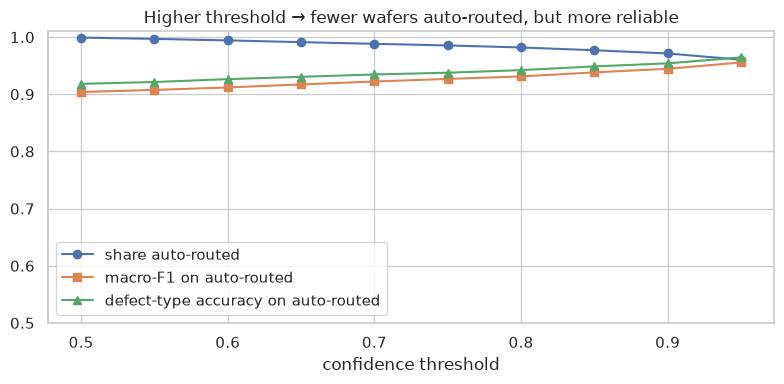

In [10]:
thresholds = np.round(np.arange(0.5, 1.0, 0.05), 2)
rows = []
for th in thresholds:
    sure = confidence >= th
    rows.append({
        "threshold": th,
        "coverage (auto-routed)": sure.mean(),
        "macro_F1 when sure": f1_score(y_test[sure], y_pred[sure], average="macro"),
        "accuracy when sure": accuracy_score(y_test[sure], y_pred[sure]),
        "accuracy on defects when sure": accuracy_score(y_test[sure & (y_test != "none")],
                                                        y_pred[sure & (y_test != "none")]),
        "to engineer": int((~sure).sum()),
    })
conf_tbl = pd.DataFrame(rows)
display(conf_tbl.round(3))

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(conf_tbl["threshold"], conf_tbl["coverage (auto-routed)"], "o-", label="share auto-routed")
ax.plot(conf_tbl["threshold"], conf_tbl["macro_F1 when sure"], "s-", label="macro-F1 on auto-routed")
ax.plot(conf_tbl["threshold"], conf_tbl["accuracy on defects when sure"], "^-", label="defect-type accuracy on auto-routed")
ax.set(xlabel="confidence threshold", ylim=(0.5, 1.01),
       title="Higher threshold → fewer wafers auto-routed, but more reliable")
ax.legend(); plt.tight_layout(); savefig("confidence_tradeoff"); plt.show()

## Summary for the slides

**Performance holds up on unseen lots.** Test macro-F1 **0.901** vs 0.896 in cross-validation (baseline 0.102);
defect recall 95.5% vs 95.1%. The lot-grouped validation gave an honest estimate.

**Business view (34,585 test wafers):**
- **95.5%** of real defect wafers are flagged (232 missed); **94.7%** of flags are real defects (271 false alarms).
- Engineers would review **14.9%** of wafers (5,144) instead of all of them.
- When a real defect is flagged, the defect **type is correct 96.0%** of the time.

**Where it fails:**
- Strong classes: Near-full (1.00 recall), Edge-Ring (0.99), Center (0.94), Random (0.91), Edge-Loc (0.90).
- Weak classes: **Scratch (0.74)** and **Loc (0.78)** — most of their misses are predicted as `none` (15% and 10%).
  Thin scratches and small local blobs involve few dies and are easily lost among random background defects.
- The error examples are mostly **faint, borderline patterns** that are ambiguous even by eye; some look
  mislabelled. This is partly a label-quality ceiling, not only a model limit.
- **Wafer size:** most reliable on very large wafers (macro-F1 0.93, defect recall 97.9%); weakest on
  medium wafers (0.85, 91.8%) — fewer dies means a pattern is made of fewer pixels.

**Confidence threshold (input to the deployment recommendation):** auto-routing only predictions with
confidence ≥ 0.90 covers **97.1%** of wafers with macro-F1 0.945; the remaining ~2.9% (993 wafers)
go to an engineer. This supports a **human-in-the-loop** deployment.
